# Zajęcia 1 — Sekwencje i sygnał mowy
## Od fali dźwiękowej do reprezentacji dla sieci neuronowych

**Cel:** wczytać sygnał mowy (16 kHz, mono) i wyliczyć trzy reprezentacje:
spektrogram log-mel oraz MFCC; zbadać wpływ parametrów `n_fft` i `hop_length`.

Uruchom komórki po kolei (Shift+Enter). Bez własnego pliku audio notebook
użyje sygnału syntetycznego, aby ćwiczenie działało od razu.

*Prowadzący: dr Tomasz Cieplak / mgr inż. Patryk Marek, Rok akademicki: 2026/27*

## 1. Instalacja bibliotek

In [1]:
#!pip -q install librosa soundfile matplotlib numpy

## 2. Import i parametry

Parametry `N_FFT` i `HOP_LENGTH` zmieniasz w zadaniu — obserwuj wpływ na spektrogram.

In [2]:
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt

SR = 16000          # częstotliwość próbkowania [Hz] — standard w ASR
N_FFT = 512         # długość okna FFT
HOP_LENGTH = 160    # przesunięcie ramki (10 ms przy 16 kHz)
N_MELS = 64         # liczba pasm mel

## 3. Wczytanie audio

Aby użyć **własnego nagrania**, odkomentuj komórkę z `files.upload()`,
wgraj plik `.wav`, a następnie w wywołaniu `wczytaj_audio(...)` podaj jego nazwę.

In [3]:
# from google.colab import files
# uploaded = files.upload()   # wybierz plik .wav z dysku

def wczytaj_audio(sciezka=None):
    """Wczytuje audio do 16 kHz mono. Bez pliku zwraca sygnał syntetyczny."""
    if sciezka:
        y, sr = librosa.load(sciezka, sr=SR, mono=True)
        return y.astype(np.float32), sr
    # Sygnał syntetyczny: chirp 200 Hz -> 3000 Hz, 2 s
    y = librosa.chirp(fmin=200, fmax=3000, sr=SR, duration=2.0)
    return y.astype(np.float32), SR

# Podmień None na nazwę własnego pliku, np. 'moje_nagranie.wav'
y, sr = wczytaj_audio(None)

print(f"Liczba próbek: {len(y)}")
print(f"Częstotliwość próbkowania: {sr} Hz")
print(f"Czas trwania: {len(y) / sr:.2f} s")

Liczba próbek: 32000
Częstotliwość próbkowania: 16000 Hz
Czas trwania: 2.00 s


## 4. Odsłuch (opcjonalnie)

In [4]:
from IPython.display import Audio
Audio(y, rate=sr)

## 5. Reprezentacje: log-mel i MFCC

In [5]:
def log_mel(y, sr, n_fft=N_FFT, hop_length=HOP_LENGTH, n_mels=N_MELS):
    S = librosa.feature.melspectrogram(
        y=y, sr=sr, n_fft=n_fft, hop_length=hop_length, n_mels=n_mels
    )
    return librosa.power_to_db(S, ref=np.max)

def mfcc(y, sr, n_mfcc=13):
    return librosa.feature.mfcc(
        y=y, sr=sr, n_mfcc=n_mfcc, n_fft=N_FFT, hop_length=HOP_LENGTH
    )

S_db = log_mel(y, sr)
M = mfcc(y, sr)
print(f"Kształt log-mel: {S_db.shape}  (pasma mel × ramki czasowe)")
print(f"Kształt MFCC:    {M.shape}  (współczynniki × ramki czasowe)")

Kształt log-mel: (64, 201)  (pasma mel × ramki czasowe)
Kształt MFCC:    (13, 201)  (współczynniki × ramki czasowe)


## 6. Wizualizacja

Trzy reprezentacje tego samego nagrania: przebieg czasowy, log-mel, MFCC.

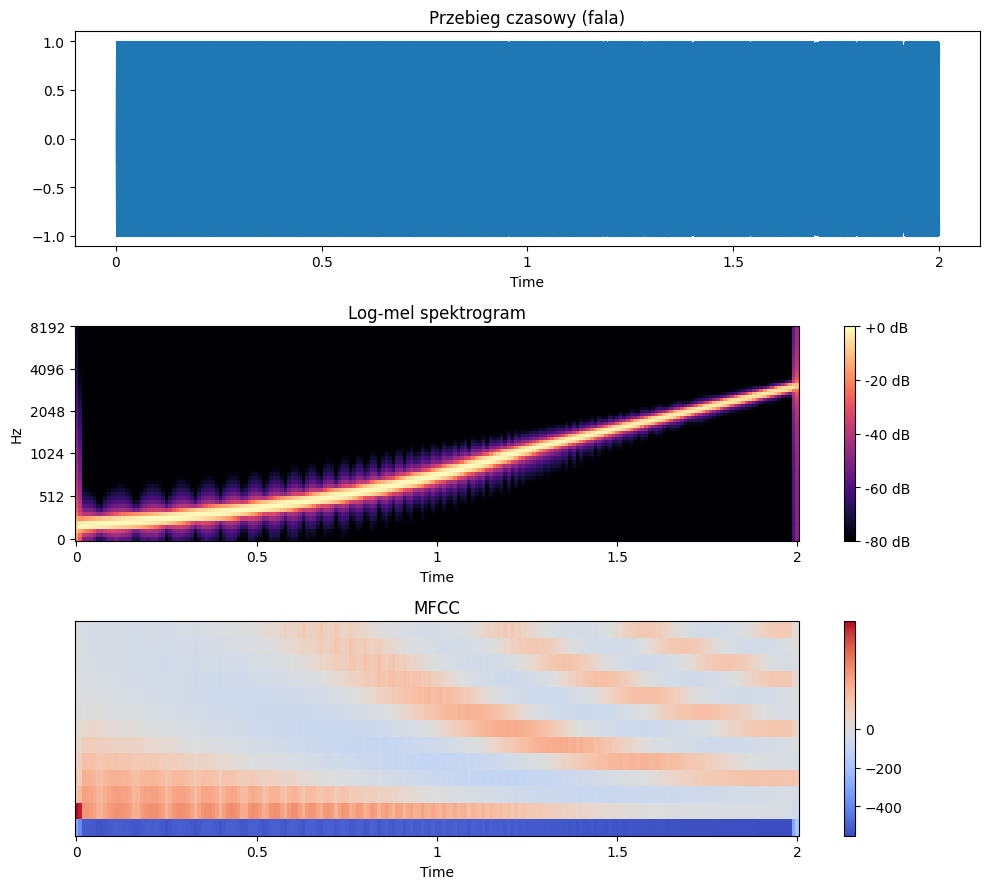

In [6]:
fig, ax = plt.subplots(3, 1, figsize=(10, 9))

librosa.display.waveshow(y, sr=sr, ax=ax[0])
ax[0].set_title("Przebieg czasowy (fala)")

img1 = librosa.display.specshow(
    S_db, sr=sr, hop_length=HOP_LENGTH, x_axis="time", y_axis="mel", ax=ax[1]
)
ax[1].set_title("Log-mel spektrogram")
fig.colorbar(img1, ax=ax[1], format="%+2.0f dB")

img2 = librosa.display.specshow(
    M, sr=sr, hop_length=HOP_LENGTH, x_axis="time", ax=ax[2]
)
ax[2].set_title("MFCC")
fig.colorbar(img2, ax=ax[2])

plt.tight_layout()
plt.show()

## Zadanie na sprawozdanie

Dla **trzech własnych nagrań** (samogłoska, wyraz, całe zdanie):

1. Wczytaj każde do 16 kHz mono.
2. Wygeneruj przebieg czasowy, log-mel i MFCC.
3. Porównaj reprezentacje między nagraniami — co się różni?
4. Zmień `N_FFT` (np. 256, 1024) i `HOP_LENGTH`; opisz wpływ na spektrogram
   (kompromis rozdzielczość czasowa vs częstotliwościowa).
5. Wnioski: które cechy widać w mowie ciągłej, a które w pojedynczej głosce?

Format sprawozdania: `00_materialy_wspolne/szablon_sprawozdania.md`.

In [7]:
pliki = {
    "samogloska": "a.wav",
    "wyraz": "Wyraz.wav",
    "zdanie": "Zdanie.wav",
}

In [8]:
nagrania = {}
for nazwa, plik in pliki.items():
    y, sr = librosa.load(plik, sr=16000, mono=True)
    nagrania[nazwa] = y
    print(f"{nazwa}: {len(y)} próbek, {len(y)/sr:.2f} s")

samogloska: 32086 próbek, 2.01 s
wyraz: 28672 próbek, 1.79 s
zdanie: 38571 próbek, 2.41 s


In [9]:
for nazwa, y in nagrania.items():
    print(nazwa)
    display(Audio(y, rate= 16000))

samogloska


wyraz


zdanie


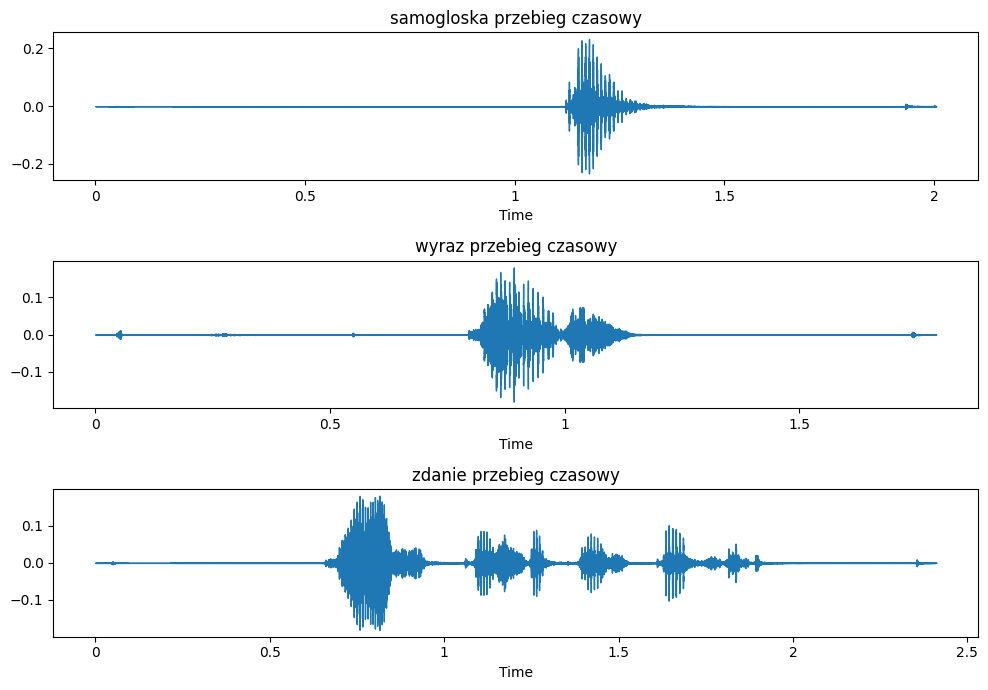

In [10]:
fig, ax = plt.subplots(3, 1, figsize=(10, 7))
for a, (nazwa, y) in zip(ax, nagrania.items()):
    librosa.display.waveshow(y, sr=SR, ax=a)
    a.set_title(f"{nazwa} przebieg czasowy")
plt.tight_layout()
plt.savefig("przebiegi.png", dpi=150)
plt.show()

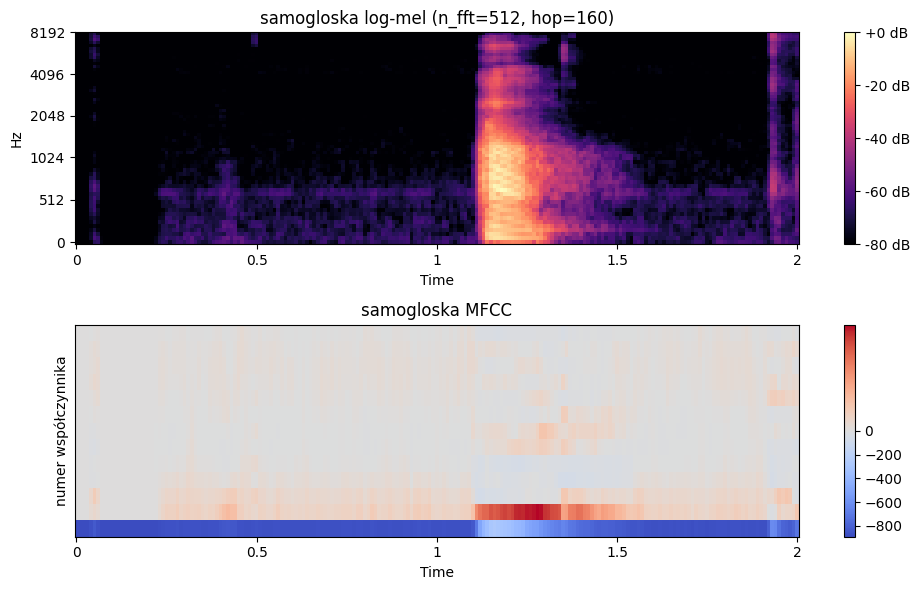

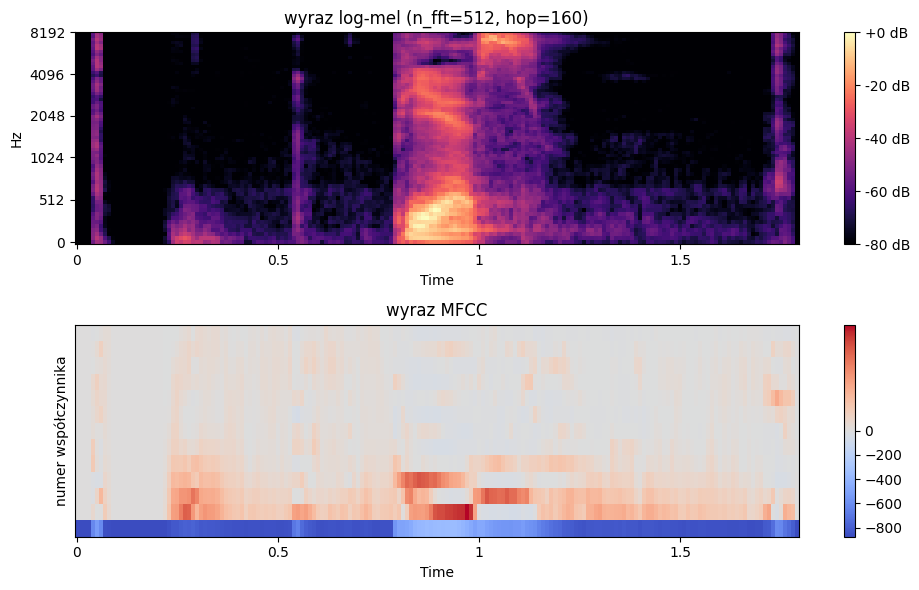

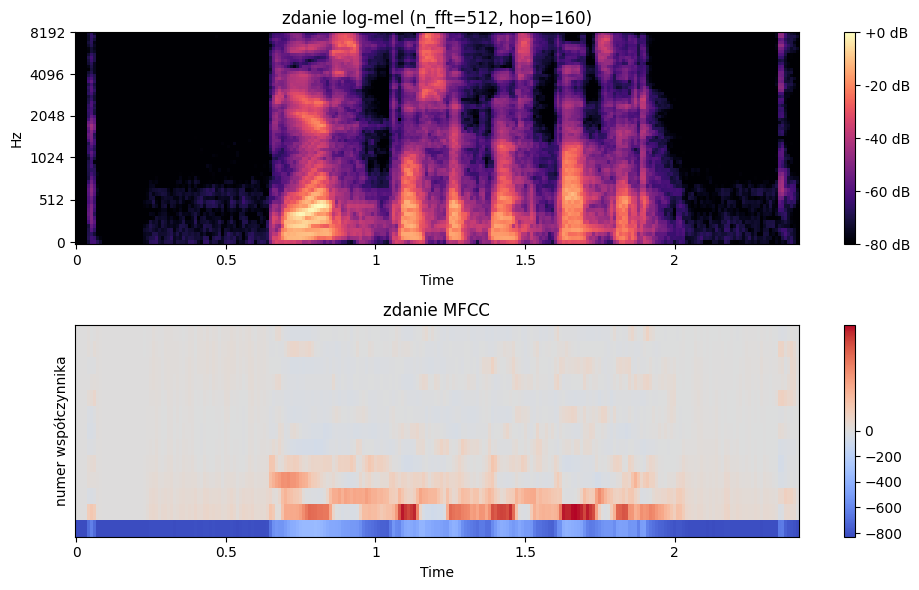

In [11]:
def log_mel(y, sr, n_fft=512, hop_length=160, n_mels=64):
    S = librosa.feature.melspectrogram(y=y, sr=sr, n_fft=n_fft,
                                       hop_length=hop_length, n_mels=n_mels)
    return librosa.power_to_db(S, ref=np.max)

def mfcc(y, sr, n_fft=512, hop_length=160, n_mfcc=13):
    return librosa.feature.mfcc(y=y, sr=sr, n_mfcc=n_mfcc,
                                n_fft=n_fft, hop_length=hop_length)

def rysuj(nazwa, y, n_fft=512, hop=160):
    S_db = log_mel(y, SR, n_fft, hop)
    M = mfcc(y, SR, n_fft, hop)
    fig, ax = plt.subplots(2, 1, figsize=(10, 6))
    im1 = librosa.display.specshow(S_db, sr=SR, hop_length=hop, x_axis="time",
                                   y_axis="mel", vmin=-80, vmax=0, ax=ax[0])
    ax[0].set_title(f"{nazwa} log-mel (n_fft={n_fft}, hop={hop})")
    fig.colorbar(im1, ax=ax[0], format="%+2.0f dB")
    im2 = librosa.display.specshow(M, sr=SR, hop_length=hop, x_axis="time", ax=ax[1])
    ax[1].set_title(f"{nazwa} MFCC")
    ax[1].set_ylabel("numer współczynnika")
    fig.colorbar(im2, ax=ax[1])
    plt.tight_layout()
    plt.savefig(f"{nazwa}_n{n_fft}_h{hop}.png", dpi=150)
    plt.show()

for nazwa, y in nagrania.items():
    rysuj(nazwa, y)

In [12]:
for nazwa, y in nagrania.items():
    print(nazwa, "log-mel:", log_mel(y, SR).shape, "MFCC:", mfcc(y, SR).shape)

samogloska log-mel: (64, 201) MFCC: (13, 201)
wyraz log-mel: (64, 180) MFCC: (13, 180)
zdanie log-mel: (64, 242) MFCC: (13, 242)


/opt/anaconda3/envs/103983/lib/python3.12/site-packages/librosa/feature/spectral.py:2170: UserWarning: Empty filters detected in mel frequency basis. Some channels will produce empty responses. Try increasing your sampling rate (and fmax) or reducing n_mels.
  mel_basis = filters.mel(sr=sr, n_fft=n_fft, **kwargs)


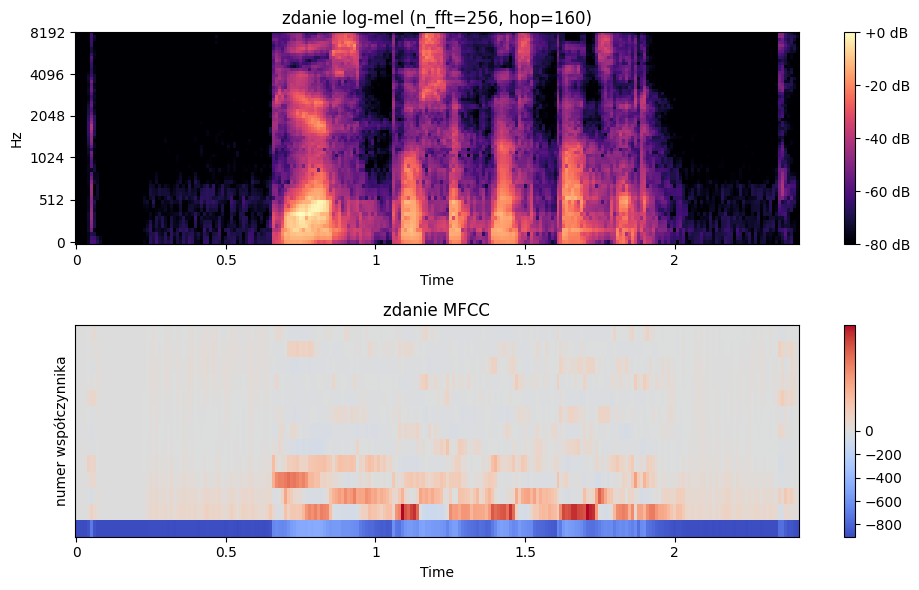

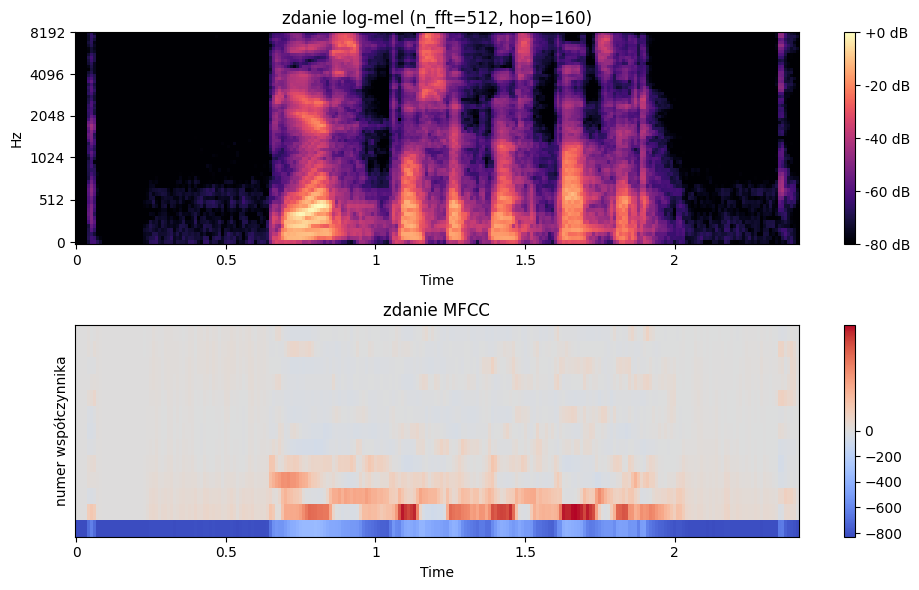

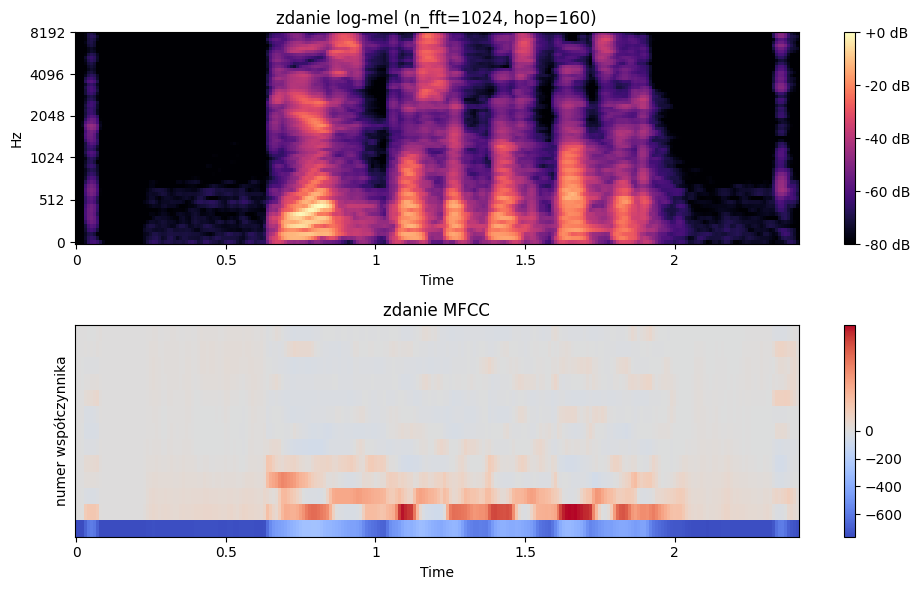

In [13]:
y = nagrania["zdanie"]
for n_fft in (256, 512, 1024):
    rysuj("zdanie", y, n_fft=n_fft, hop=160)

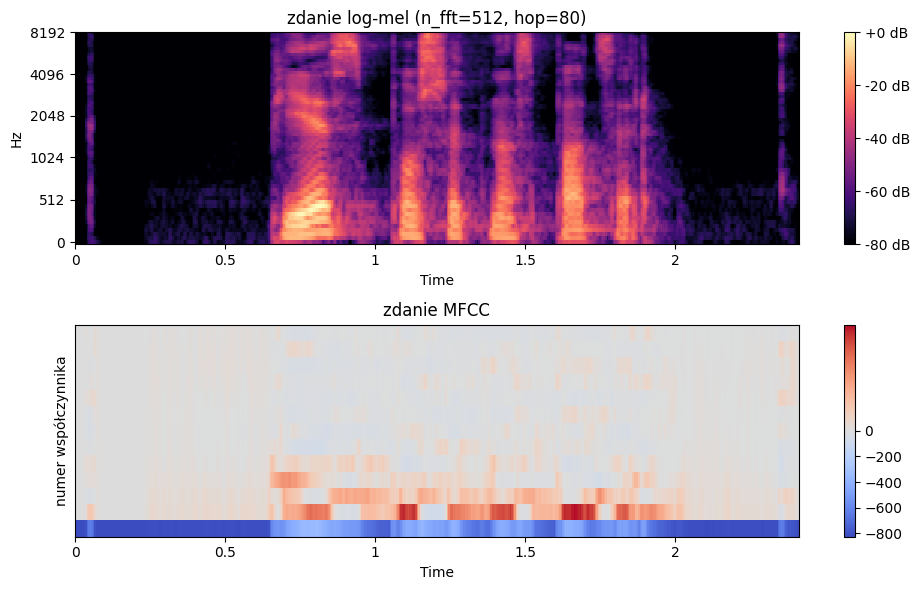

hop 80 -> ramek: 483


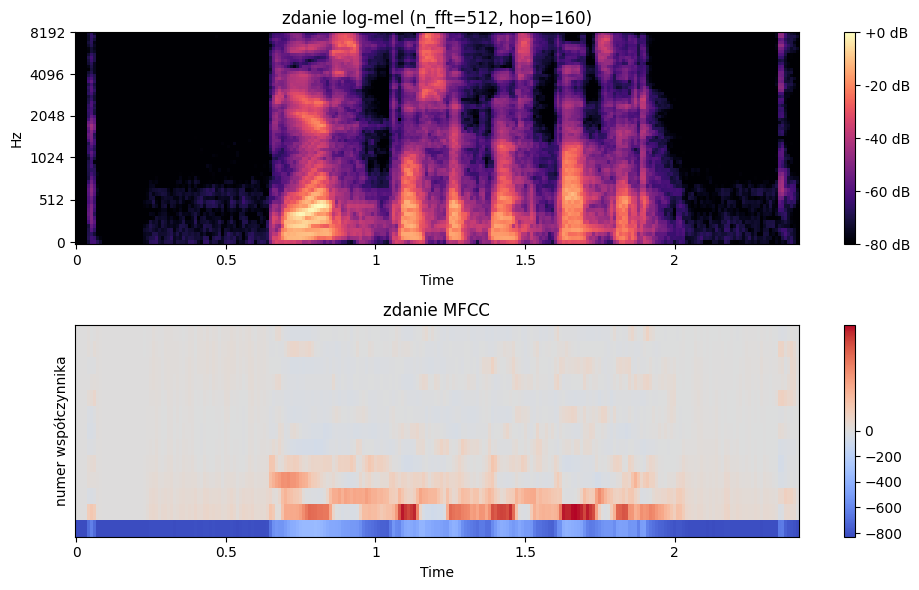

hop 160 -> ramek: 242


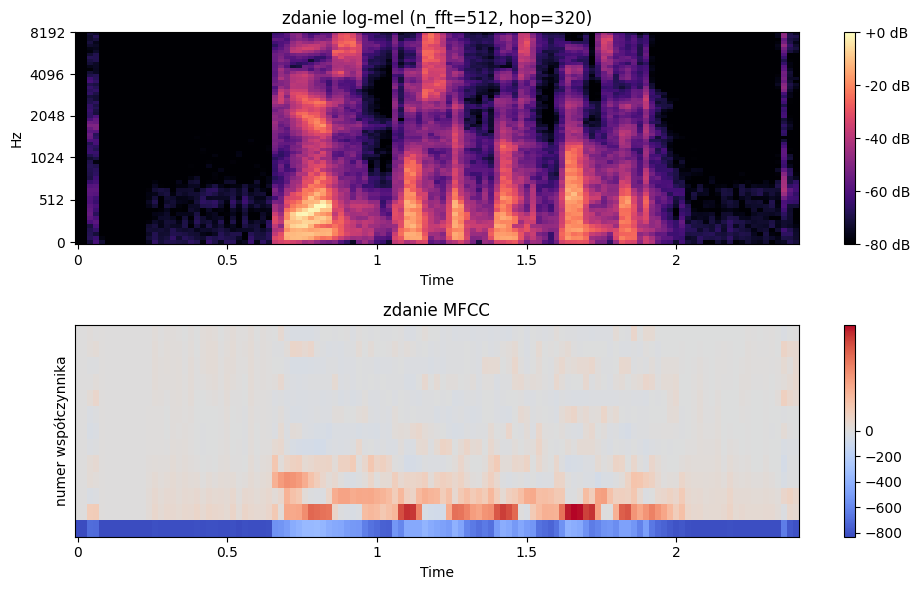

hop 320 -> ramek: 121


In [14]:
for hop in (80, 160, 320):
    rysuj("zdanie", y, n_fft=512, hop=hop)
    print("hop", hop, "-> ramek:", log_mel(y, SR, 512, hop).shape[1])

In [15]:
for nazwa, y in nagrania.items():
    print(nazwa, "log-mel:", log_mel(y, SR).shape, "MFCC:", mfcc(y, SR).shape)
for hop in (80, 160, 320):
    print("hop", hop, "-> ramek:", log_mel(nagrania["zdanie"], SR, 512, hop).shape[1])

samogloska log-mel: (64, 201) MFCC: (13, 201)
wyraz log-mel: (64, 180) MFCC: (13, 180)
zdanie log-mel: (64, 242) MFCC: (13, 242)
hop 80 -> ramek: 483
hop 160 -> ramek: 242
hop 320 -> ramek: 121
